In [5]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:
# Load the solar power generation dataset

df = pd.read_csv(r"D:\Plant_1_Generation_Data.csv")

# Display first 5 rows
print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
df.head()

Dataset loaded successfully!
Total records: 68778
Total columns: 7


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [9]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
df.info()

Dataset Shape: (68778, 7)

Column Names:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']
<class 'pandas.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  str    
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  str    
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), str(2)
memory usage: 3.7 MB


In [10]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

Missing Values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,68778.0,68778.000000,68778.000000,68778.000000,6.877800e+04
mean,4135001.0,3147.426211,307.802752,3295.968737,6.978712e+06
std,0.0,4036.457169,394.396439,3145.178309,4.162720e+05
min,4135001.0,0.000000,0.000000,0.000000,6.183645e+06
25%,4135001.0,0.000000,0.000000,0.000000,6.512003e+06
50%,4135001.0,429.000000,41.493750,2658.714286,7.146685e+06
75%,4135001.0,6366.964286,623.618750,6274.000000,7.268706e+06
max,4135001.0,14471.125000,1410.950000,9163.000000,7.846821e+06


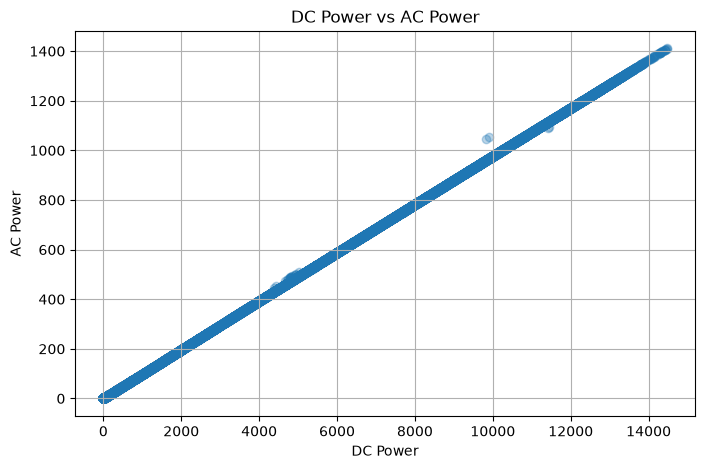

In [11]:
# Visualize DC Power and AC Power

plt.figure(figsize=(8, 5))

plt.scatter(df["DC_POWER"], df["AC_POWER"], alpha=0.3)

plt.title("DC Power vs AC Power")
plt.xlabel("DC Power")
plt.ylabel("AC Power")

plt.grid(True)
plt.show()

In [12]:
# Calculate correlation between DC_POWER and AC_POWER

correlation = df["DC_POWER"].corr(df["AC_POWER"])

print("Correlation between DC_POWER and AC_POWER:", round(correlation, 4))

Correlation between DC_POWER and AC_POWER: 1.0


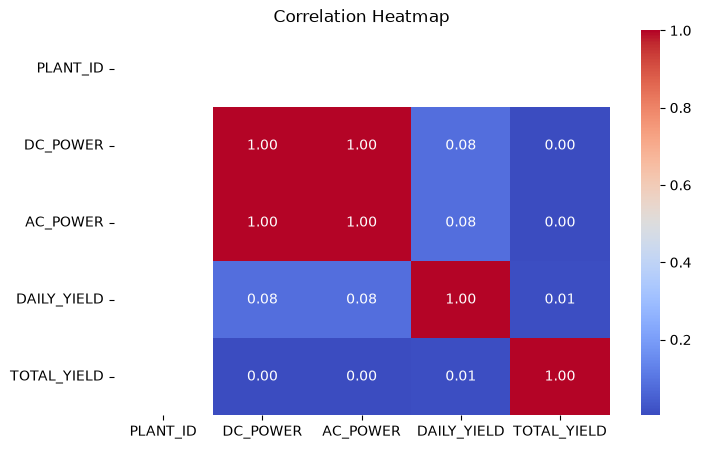

In [13]:
# Correlation heatmap for numerical columns

plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [14]:
X = df[["DC_POWER"]]
y = df["AC_POWER"]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

Input Shape: (68778, 1)
Target Shape: (68778,)


,DC_POWER
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: AC_POWER, dtype: float64

In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (55022, 1)
Testing data: (13756, 1)


In [16]:
# Create and train Linear Regression model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [17]:
# Predict AC_POWER using the test data

y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual AC_POWER": y_test.values,
    "Predicted AC_POWER": y_pred
})

display(results.head(10))

,Actual AC_POWER,Predicted AC_POWER
0,0.000000,0.274128
1,0.000000,0.274128
2,718.062500,716.838222
3,0.000000,0.274128
4,750.437500,749.239997
5,0.000000,0.274128
6,0.000000,0.274128
7,358.714286,357.990003
8,93.512500,94.352858
9,398.687500,396.838634


In [18]:
# Evaluate Linear Regression model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE : 0.7148
MSE : 2.1368
RMSE: 1.4618
R² Score: 1.0


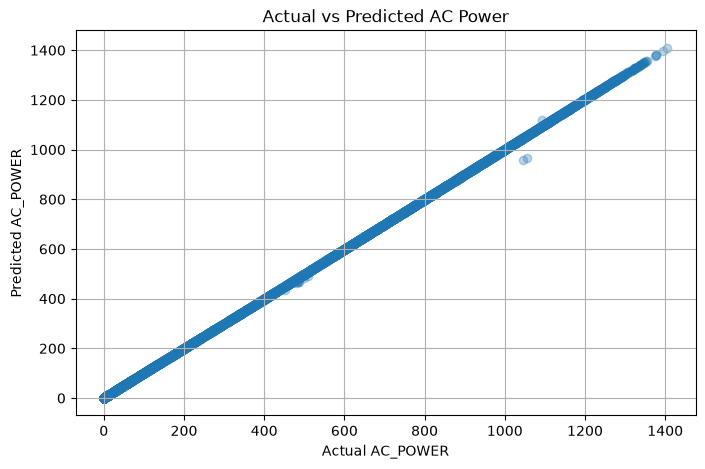

In [19]:
# Compare actual and predicted AC_POWER

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual AC_POWER")
plt.ylabel("Predicted AC_POWER")
plt.title("Actual vs Predicted AC Power")

plt.grid(True)
plt.show()

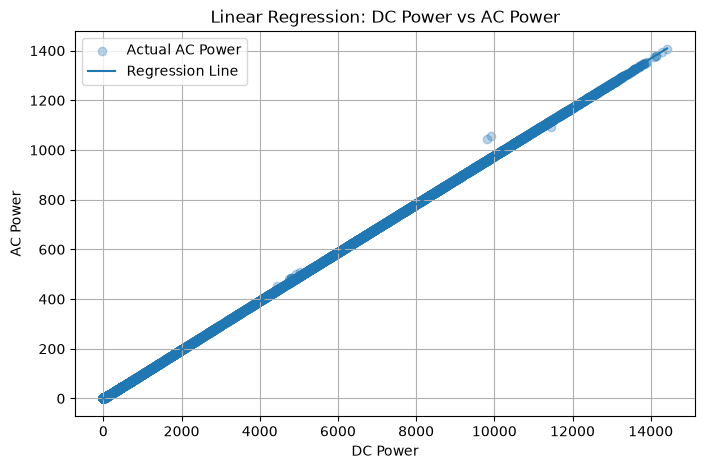

In [20]:
# Plot Regression Line

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["DC_POWER"],
    y_test,
    alpha=0.3,
    label="Actual AC Power"
)

# Sort input values for a smooth regression line
sorted_indices = np.argsort(X_test["DC_POWER"].values)

x_sorted = X_test["DC_POWER"].values[sorted_indices]
y_sorted = y_pred[sorted_indices]

plt.plot(
    x_sorted,
    y_sorted,
    label="Regression Line"
)

plt.xlabel("DC Power")
plt.ylabel("AC Power")
plt.title("Linear Regression: DC Power vs AC Power")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Predict AC_POWER for a new DC_POWER value

new_data = pd.DataFrame({
    "DC_POWER": [1000.0]
})

predicted_power = model.predict(new_data)

print("Input DC Power:", new_data["DC_POWER"].iloc[0])
print("Predicted AC Power:", round(predicted_power[0], 2))

Input DC Power: 1000.0
Predicted AC Power: 97.98
